# Taller: Cálculo del TF, IDF y TF-IDF

## Ayala Christian

### Objetivo

Calcular los valores de **TF** (Term Frequency), **IDF** (Inverse Document Frequency) y **TF-IDF** para los términos de una colección de **100 documentos** extraídos del archivo `txt-files.tar.zip` (Proyecto Gutenberg).

#### Fórmulas utilizadas

**TF (Term Frequency):**

- TF crudo: $\text{tf}(t, d) = f_{t,d}$ (frecuencia del término $t$ en el documento $d$)
- TF normalizado: $\text{tf}(t, d) = \dfrac{f_{t,d}}{\max\{f_{t',d} : t' \in d\}}$

**IDF (Inverse Document Frequency):**

1. $\text{idf}(t) = \log_{10}\left(\dfrac{N}{\text{df}(t)}\right)$

2. $\text{idf}(t) = \ln\left(\dfrac{N}{\text{df}(t)}\right) + 1$

**TF-IDF:**

$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \text{idf}(t)$

Donde:
- $N$ = número total de documentos en la colección
- $\text{df}(t)$ = número de documentos que contienen el término $t$
- $f_{t,d}$ = número de veces que el término $t$ aparece en el documento $d$

## 1. Importaciones y configuración inicial

In [1]:
import re
import math
import zipfile
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict, Counter

# Configuración de visualización
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', '{:.6f}'.format)
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Carga y preparación del corpus (100 documentos)

Extraemos 100 documentos del archivo `txt-files.tar.zip`, aplicando la misma estrategia de deduplicación y tokenización que en el notebook de referencia.

In [2]:
CARPETA = Path.cwd()
RUTA_ZIP = CARPETA / "txt-files.tar.zip"
TAMANO_CORPUS = 100

# ── Tokenización y normalización ──
def tokenizar(texto):
    """Convierte a minúsculas y extrae tokens alfanuméricos."""
    texto = texto.lower()
    return re.findall(r'\b[a-z0-9]+\b', texto)


# ── Identificar archivos TXT dentro del ZIP/TAR ──
with zipfile.ZipFile(RUTA_ZIP, "r") as zf:
    nombres_zip = zf.namelist()

    txt_directos = [
        n for n in nombres_zip
        if n.lower().endswith(".txt")
        and not n.endswith("/")
    ]

    tar_interno = next(
        (n for n in nombres_zip if n.lower().endswith(".tar")),
        None
    )

    if txt_directos:
        tipo_archivo = "zip_txt"
        nombres_txt = txt_directos
    elif tar_interno:
        tipo_archivo = "tar_interno"
        nombres_txt = []
        with zf.open(tar_interno) as archivo_tar:
            with tarfile.open(fileobj=archivo_tar, mode="r|") as tf:
                for miembro in tf:
                    if miembro.isfile() and miembro.name.lower().endswith(".txt"):
                        nombres_txt.append(miembro.name)
    else:
        raise ValueError("No se encontraron TXT ni un TAR dentro del ZIP.")


# ── Deduplicación por nombre ──
def clave_documento(nombre):
    nombre = Path(nombre).name.lower()
    nombre = re.sub(r"-\d+\.txt$", ".txt", nombre)
    return nombre


archivos_unicos = {}
for nombre in sorted(nombres_txt):
    archivos_unicos.setdefault(clave_documento(nombre), nombre)

lista_corpus = list(archivos_unicos.values())

print(f"Tipo de archivo: {tipo_archivo}")
print(f"Archivos TXT totales identificados: {len(nombres_txt)}")
print(f"Documentos tras deduplicación: {len(lista_corpus)}")
print(f"Documentos a utilizar: {TAMANO_CORPUS}")

Tipo de archivo: tar_interno
Archivos TXT totales identificados: 78145
Documentos tras deduplicación: 78145
Documentos a utilizar: 100


In [3]:
# ── Extracción y tokenización de los 100 documentos ──
seleccion = lista_corpus[:TAMANO_CORPUS]
documentos = {}

if tipo_archivo == "zip_txt":
    with zipfile.ZipFile(RUTA_ZIP, "r") as zf:
        for nombre in seleccion:
            with zf.open(nombre) as f:
                texto = f.read().decode("utf-8", errors="ignore")
            documentos[nombre] = tokenizar(texto)
else:
    pendientes = set(seleccion)
    with zipfile.ZipFile(RUTA_ZIP, "r") as zf:
        with zf.open(tar_interno) as archivo_tar:
            with tarfile.open(fileobj=archivo_tar, mode="r|") as tf:
                for miembro in tf:
                    if miembro.name not in pendientes:
                        continue
                    f = tf.extractfile(miembro)
                    if f is None:
                        continue
                    texto = f.read().decode("utf-8", errors="ignore")
                    documentos[miembro.name] = tokenizar(texto)
                    pendientes.remove(miembro.name)
                    if not pendientes:
                        break

N = len(documentos)
total_tokens = sum(len(t) for t in documentos.values())

print(f"Documentos procesados: {N}")
print(f"Total de tokens: {total_tokens:,}")

# Mostrar tabla con los primeros documentos
tabla_docs = pd.DataFrame([
    {
        "Documento": Path(nombre).name,
        "Tokens": len(tokens)
    }
    for nombre, tokens in list(documentos.items())[:15]
])
display(tabla_docs)

Documentos procesados: 100
Total de tokens: 7,370,211


,Documento,Tokens
0,pg10000.txt,17741
1,pg10001.txt,8765
2,pg10002.txt,54686
3,pg10003.txt,65599
4,pg10004.txt,52184
5,pg10005.txt,74098
6,pg10006.txt,16451
7,pg10007.txt,31478
8,pg10008.txt,70986
9,pg10009.txt,91242


---
## 3. Cálculo del TF (Term Frequency)

El **TF** mide la frecuencia de un término dentro de un documento específico. Calculamos dos variantes:

- **TF crudo**: $\text{tf}(t, d) = f_{t,d}$ — Conteo directo de apariciones del término $t$ en el documento $d$.
- **TF normalizado**: $\text{tf}(t, d) = \dfrac{f_{t,d}}{\max\{f_{t',d} : t' \in d\}}$ — Normalizado dividiendo por la frecuencia del término más frecuente en el documento.

In [18]:
# ── Calcular TF crudo para cada documento ──
# tf_crudo[doc][termino] = frecuencia del término en ese documento
tf_crudo = {}
for doc, tokens in documentos.items():
    tf_crudo[doc] = Counter(tokens)

# ── Calcular TF normalizado para cada documento ──
# tf_norm[doc][termino] = f(t,d) / max_f(d)
tf_norm = {}
for doc, conteo in tf_crudo.items():
    max_freq = max(conteo.values())
    tf_norm[doc] = {t: freq / max_freq for t, freq in conteo.items()}

print(f"TF calculado para {len(tf_crudo)} documentos.")
print(f"\nEjemplo — TF del primer documento:")

primer_doc = list(documentos.keys())[0]
primer_doc_nombre = Path(primer_doc).name
print(f"  Documento: {primer_doc_nombre}")
print(f"  Total tokens: {len(documentos[primer_doc]):,}")
print(f"  Términos únicos: {len(tf_crudo[primer_doc]):,}")

# Mostrar top 15 términos más frecuentes del primer documento
top_tf = tf_crudo[primer_doc].most_common(15)
tabla_tf_ejemplo = pd.DataFrame([
    {
        "Término": t,
        "TF crudo f(t,d)": freq,
        "TF normalizado": tf_norm[primer_doc][t]
    }
    for t, freq in top_tf
])
print(f"\n  Top 15 términos más frecuentes en '{primer_doc_nombre}':")
display(tabla_tf_ejemplo)

TF calculado para 100 documentos.

Ejemplo — TF del primer documento:
  Documento: pg10000.txt
  Total tokens: 17,741
  Términos únicos: 1,870

  Top 15 términos más frecuentes en 'pg10000.txt':


,Término,"TF crudo f(t,d)",TF normalizado
0,the,1144,1.000000
1,of,902,0.788462
2,and,672,0.587413
3,to,489,0.427448
4,or,365,0.319056
5,in,344,0.300699
6,shall,328,0.286713
7,be,287,0.250874
8,our,259,0.226399
9,we,221,0.193182


In [5]:
# ── TF de términos seleccionados en múltiples documentos ──
terminos_tf = ["the", "love", "war", "god", "death", "king"]
docs_muestra = list(documentos.keys())[:10]

filas_tf = []
for doc in docs_muestra:
    doc_nombre = Path(doc).name
    for t in terminos_tf:
        freq = tf_crudo[doc].get(t, 0)
        norm = tf_norm[doc].get(t, 0.0)
        filas_tf.append({
            "Documento": doc_nombre,
            "Término": t,
            "TF crudo": freq,
            "TF normalizado": norm
        })

df_tf_muestra = pd.DataFrame(filas_tf)

# Mostrar como tabla pivote
print("TF crudo de términos seleccionados en los primeros 10 documentos:")
pivot_crudo = df_tf_muestra.pivot(index="Documento", columns="Término", values="TF crudo")
pivot_crudo = pivot_crudo[terminos_tf]  # Mantener orden
display(pivot_crudo)

print("\nTF normalizado de los mismos términos:")
pivot_norm = df_tf_muestra.pivot(index="Documento", columns="Término", values="TF normalizado")
pivot_norm = pivot_norm[terminos_tf]
display(pivot_norm)

TF crudo de términos seleccionados en los primeros 10 documentos:


Término,the,love,war,god,death,king
Documento,,,,,,
pg10000.txt,1144,0,18,15,17,21
pg10001.txt,460,0,0,13,2,3
pg10002.txt,3848,8,0,16,11,0
pg10003.txt,4244,7,29,1,14,35
pg10004.txt,3496,59,11,148,17,13
pg10005.txt,4958,30,2,4,16,3
pg10006.txt,823,57,1,11,7,1
pg10007.txt,1609,13,0,7,15,0
pg10008.txt,4836,3,7,28,14,1



TF normalizado de los mismos términos:


Término,the,love,war,god,death,king
Documento,,,,,,
pg10000.txt,1.000000,0.000000,0.015734,0.013112,0.014860,0.018357
pg10001.txt,1.000000,0.000000,0.000000,0.028261,0.004348,0.006522
pg10002.txt,1.000000,0.002079,0.000000,0.004158,0.002859,0.000000
pg10003.txt,1.000000,0.001649,0.006833,0.000236,0.003299,0.008247
pg10004.txt,1.000000,0.016876,0.003146,0.042334,0.004863,0.003719
pg10005.txt,1.000000,0.006051,0.000403,0.000807,0.003227,0.000605
pg10006.txt,1.000000,0.069259,0.001215,0.013366,0.008505,0.001215
pg10007.txt,1.000000,0.008080,0.000000,0.004351,0.009323,0.000000
pg10008.txt,1.000000,0.000620,0.001447,0.005790,0.002895,0.000207


---
## 4. Construcción del índice invertido y cálculo del df(t)

Construimos el índice invertido para obtener la **frecuencia documental** `df(t)` de cada término, es decir, el número de documentos en los que aparece.

In [6]:
def construir_indice(documentos):
    """Construye un índice invertido: término → conjunto de documentos."""
    indice = defaultdict(set)
    for id_documento, tokens in documentos.items():
        for token in set(tokens):  # set() para contar cada término una sola vez por documento
            indice[token].add(id_documento)
    return dict(indice)


indice = construir_indice(documentos)

# df(t): número de documentos que contienen el término t
df_doc = {termino: len(postings) for termino, postings in indice.items()}

print(f"Términos únicos en el vocabulario: {len(indice):,}")
print(f"N (total de documentos): {N}")
print(f"\nEjemplos de df(t):")

ejemplos = ["the", "love", "war", "science", "moon", "python"]
for t in ejemplos:
    valor_df = df_doc.get(t, 0)
    print(f"  df('{t}') = {valor_df}")

Términos únicos en el vocabulario: 106,067
N (total de documentos): 100

Ejemplos de df(t):
  df('the') = 100
  df('love') = 84
  df('war') = 76
  df('science') = 56
  df('moon') = 71
  df('python') = 1


---
## 5. Cálculo del IDF con ambas fórmulas

Aplicamos las dos fórmulas de IDF a todos los términos del vocabulario:

| Fórmula | Expresión |
|---|---|
| **IDF (log₁₀)** | $\text{idf}(t) = \log_{10}\left(\dfrac{N}{\text{df}(t)}\right)$ |
| **IDF (ln + 1)** | $\text{idf}(t) = \ln\left(\dfrac{N}{\text{df}(t)}\right) + 1$ |

In [7]:
def calcular_idf_log10(N, df_t):
    """idf(t) = log10(N / df(t))"""
    if df_t == 0:
        return float('inf')
    return math.log10(N / df_t)


def calcular_idf_ln_plus1(N, df_t):
    """idf(t) = ln(N / df(t)) + 1"""
    if df_t == 0:
        return float('inf')
    return math.log(N / df_t) + 1


# Calcular IDF para todos los términos
idf_log10 = {}
idf_ln1 = {}

resultados_idf = []
for termino, df_t in df_doc.items():
    val_log10 = calcular_idf_log10(N, df_t)
    val_ln1 = calcular_idf_ln_plus1(N, df_t)
    idf_log10[termino] = val_log10
    idf_ln1[termino] = val_ln1
    resultados_idf.append({
        "Término": termino,
        "df(t)": df_t,
        "N/df(t)": round(N / df_t, 4) if df_t > 0 else float('inf'),
        "idf log₁₀(N/df(t))": val_log10,
        "idf ln(N/df(t))+1": val_ln1
    })

df_idf = pd.DataFrame(resultados_idf)
df_idf = df_idf.sort_values(by="df(t)", ascending=False).reset_index(drop=True)

print(f"Total de términos con IDF calculado: {len(df_idf):,}")
print(f"\n{'='*80}")
print("Primeros 30 términos (mayor df → menor IDF):")
print(f"{'='*80}")
display(df_idf.head(30))

Total de términos con IDF calculado: 106,067

Primeros 30 términos (mayor df → menor IDF):


,Término,df(t),N/df(t),idf log₁₀(N/df(t)),idf ln(N/df(t))+1
0,extent,100,1.000000,0.000000,1.000000
1,sent,100,1.000000,0.000000,1.000000
2,means,100,1.000000,0.000000,1.000000
3,contain,100,1.000000,0.000000,1.000000
4,concept,100,1.000000,0.000000,1.000000
5,u,100,1.000000,0.000000,1.000000
6,charge,100,1.000000,0.000000,1.000000
7,pay,100,1.000000,0.000000,1.000000
8,forth,100,1.000000,0.000000,1.000000
9,is,100,1.000000,0.000000,1.000000


## 6. Tabla de IDF para términos seleccionados

Mostramos el IDF de un conjunto de términos representativos: muy frecuentes, moderados, poco frecuentes y raros.

In [8]:
# Seleccionar términos representativos
terminos_interes = ["the", "a", "of", "and", "is", "in", "to",
                    "love", "war", "king", "god", "death",
                    "science", "moon", "river", "dream",
                    "whale", "paradise", "sword", "ocean"]

filas_seleccionadas = []
for t in terminos_interes:
    df_t = df_doc.get(t, 0)
    filas_seleccionadas.append({
        "Término": t,
        "df(t)": df_t,
        "N/df(t)": round(N / df_t, 4) if df_t > 0 else "∞",
        "idf log₁₀(N/df(t))": calcular_idf_log10(N, df_t),
        "idf ln(N/df(t))+1": calcular_idf_ln_plus1(N, df_t)
    })

df_seleccionados = pd.DataFrame(filas_seleccionadas)
print("IDF para términos seleccionados:")
print(f"N = {N} documentos\n")
display(df_seleccionados)

IDF para términos seleccionados:
N = 100 documentos



,Término,df(t),N/df(t),idf log₁₀(N/df(t)),idf ln(N/df(t))+1
0,the,100,1.000000,0.000000,1.000000
1,a,100,1.000000,0.000000,1.000000
2,of,100,1.000000,0.000000,1.000000
3,and,100,1.000000,0.000000,1.000000
4,is,100,1.000000,0.000000,1.000000
5,in,100,1.000000,0.000000,1.000000
6,to,100,1.000000,0.000000,1.000000
7,love,84,1.190500,0.075721,1.174353
8,war,76,1.315800,0.119186,1.274437
9,king,75,1.333300,0.124939,1.287682


## 7. Análisis y distribución del IDF

Analizamos estadísticas descriptivas del IDF y mostramos los términos con mayor y menor IDF.

In [9]:
# Filtrar términos con df > 0 para estadísticas
df_valido = df_idf[df_idf["df(t)"] > 0].copy()

print("Estadísticas descriptivas del IDF (fórmula log₁₀):")
print(f"{'='*50}")
print(df_valido["idf log₁₀(N/df(t))"].describe())

print(f"\nEstadísticas descriptivas del IDF (fórmula ln+1):")
print(f"{'='*50}")
print(df_valido["idf ln(N/df(t))+1"].describe())

print(f"\n\n{'='*80}")
print("Top 20 términos con MENOR IDF (más comunes):")
print(f"{'='*80}")
display(df_valido.head(20))

print(f"\n{'='*80}")
print("Top 20 términos con MAYOR IDF (más raros):")
print(f"{'='*80}")
display(df_valido.tail(20))

Estadísticas descriptivas del IDF (fórmula log₁₀):
count   106067.000000
mean         1.662316
std          0.498620
min          0.000000
25%          1.397940
50%          2.000000
75%          2.000000
max          2.000000
Name: idf log₁₀(N/df(t)), dtype: float64

Estadísticas descriptivas del IDF (fórmula ln+1):
count   106067.000000
mean         4.827625
std          1.148115
min          1.000000
25%          4.218876
50%          5.605170
75%          5.605170
max          5.605170
Name: idf ln(N/df(t))+1, dtype: float64


Top 20 términos con MENOR IDF (más comunes):


,Término,df(t),N/df(t),idf log₁₀(N/df(t)),idf ln(N/df(t))+1
0,extent,100,1.000000,0.000000,1.000000
1,sent,100,1.000000,0.000000,1.000000
2,means,100,1.000000,0.000000,1.000000
3,contain,100,1.000000,0.000000,1.000000
4,concept,100,1.000000,0.000000,1.000000
5,u,100,1.000000,0.000000,1.000000
6,charge,100,1.000000,0.000000,1.000000
7,pay,100,1.000000,0.000000,1.000000
8,forth,100,1.000000,0.000000,1.000000
9,is,100,1.000000,0.000000,1.000000



Top 20 términos con MAYOR IDF (más raros):


,Término,df(t),N/df(t),idf log₁₀(N/df(t)),idf ln(N/df(t))+1
106047,zorah,1,100.000000,2.000000,5.605170
106048,perizzites,1,100.000000,2.000000,5.605170
106049,timnath,1,100.000000,2.000000,5.605170
106050,amraphel,1,100.000000,2.000000,5.605170
106051,nagalene,1,100.000000,2.000000,5.605170
106052,konged,1,100.000000,2.000000,5.605170
106053,vaudevillian,1,100.000000,2.000000,5.605170
106054,mordelle,1,100.000000,2.000000,5.605170
106055,baseburner,1,100.000000,2.000000,5.605170
106056,detachable,1,100.000000,2.000000,5.605170


## 8. Visualización del IDF

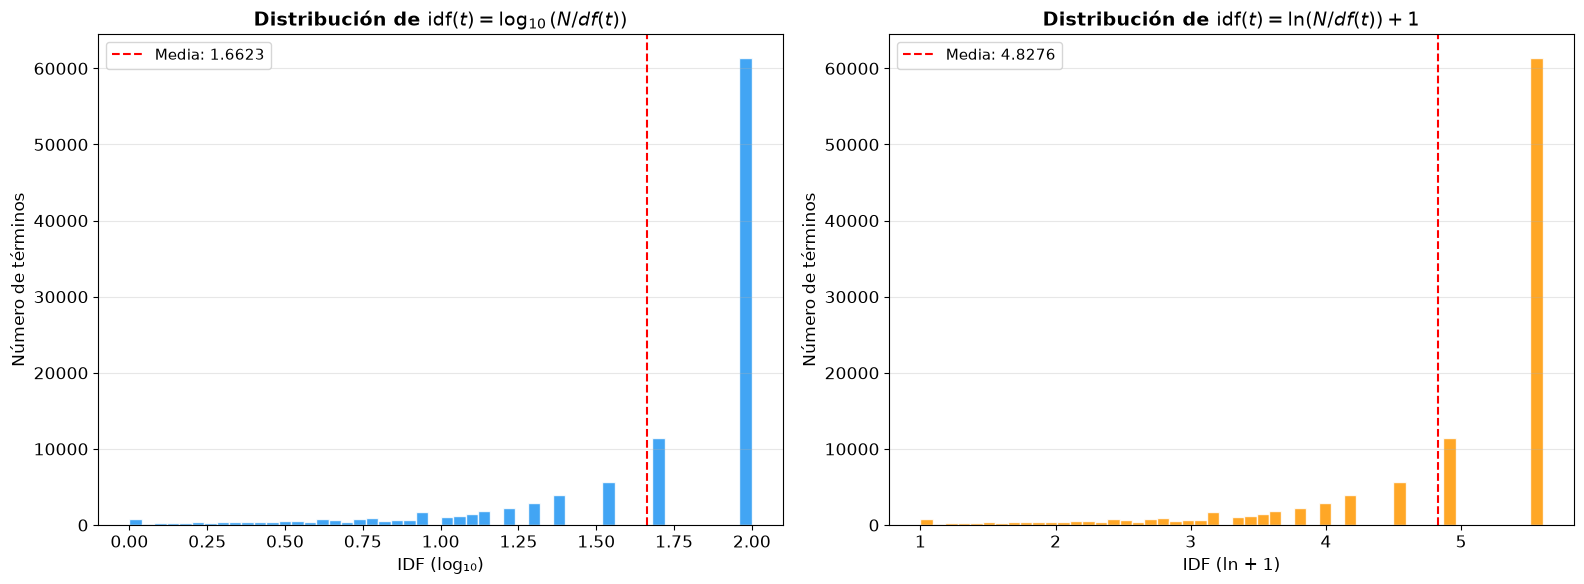

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histograma IDF log₁₀
axes[0].hist(df_valido["idf log₁₀(N/df(t))"], bins=50, color="#2196F3",
             edgecolor="white", alpha=0.85)
axes[0].set_title(r"Distribución de $\mathrm{idf}(t) = \log_{10}(N / df(t))$",
                  fontsize=14, fontweight="bold")
axes[0].set_xlabel("IDF (log₁₀)", fontsize=12)
axes[0].set_ylabel("Número de términos", fontsize=12)
axes[0].axvline(df_valido["idf log₁₀(N/df(t))"].mean(), color="red",
                linestyle="--", label=f"Media: {df_valido['idf log₁₀(N/df(t))'].mean():.4f}")
axes[0].legend(fontsize=11)
axes[0].grid(axis="y", alpha=0.3)

# Histograma IDF ln+1
axes[1].hist(df_valido["idf ln(N/df(t))+1"], bins=50, color="#FF9800",
             edgecolor="white", alpha=0.85)
axes[1].set_title(r"Distribución de $\mathrm{idf}(t) = \ln(N / df(t)) + 1$",
                  fontsize=14, fontweight="bold")
axes[1].set_xlabel("IDF (ln + 1)", fontsize=12)
axes[1].set_ylabel("Número de términos", fontsize=12)
axes[1].axvline(df_valido["idf ln(N/df(t))+1"].mean(), color="red",
                linestyle="--", label=f"Media: {df_valido['idf ln(N/df(t))+1'].mean():.4f}")
axes[1].legend(fontsize=11)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

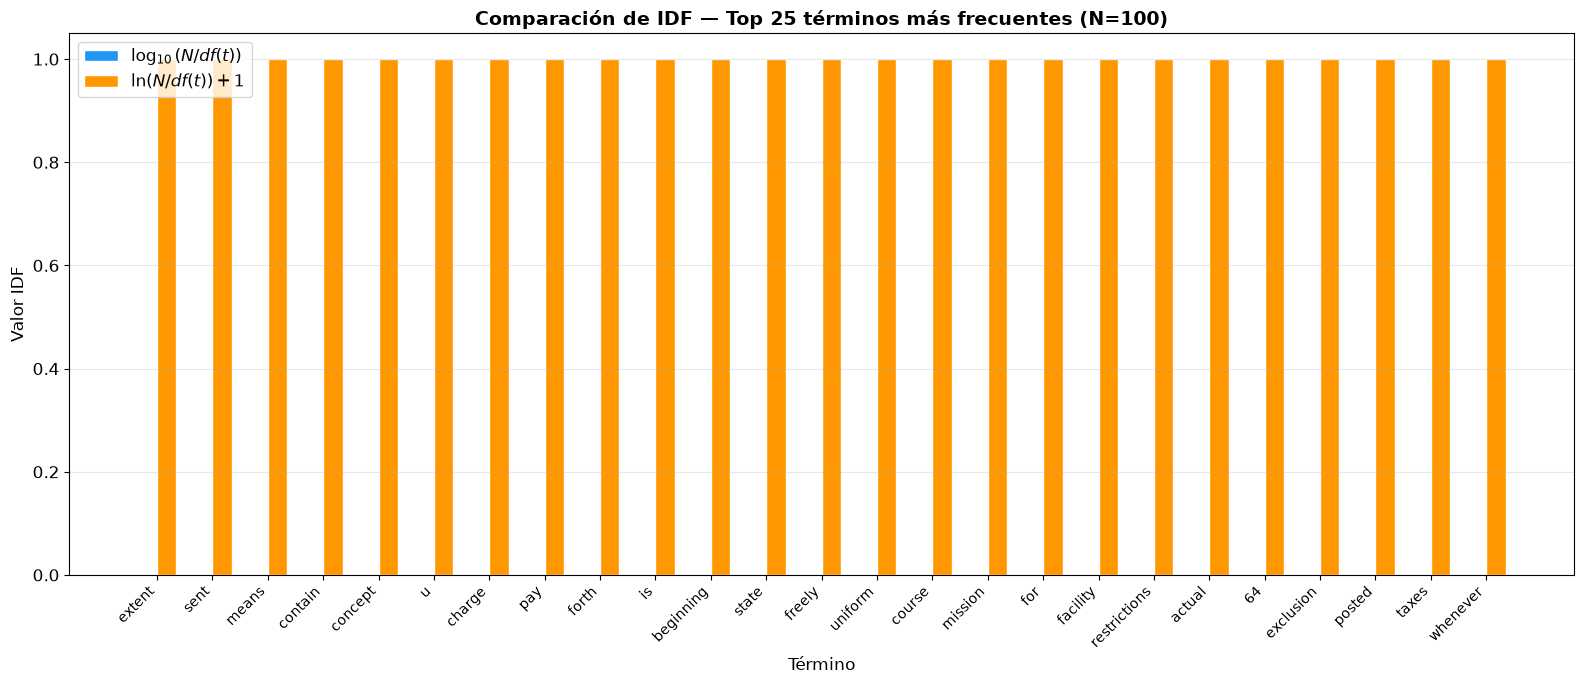

In [25]:
# Gráfica de barras comparativa: IDF de los 25 términos más frecuentes
top_n = 25
top_terminos = df_valido.head(top_n).copy()

fig, ax = plt.subplots(figsize=(16, 7))

x = np.arange(top_n)
ancho = 0.35

barras1 = ax.bar(x - ancho/2, top_terminos["idf log₁₀(N/df(t))"],
                 ancho, label=r"$\log_{10}(N/df(t))$", color="#2196F3",
                 edgecolor="white")
barras2 = ax.bar(x + ancho/2, top_terminos["idf ln(N/df(t))+1"],
                 ancho, label=r"$\ln(N/df(t)) + 1$", color="#FF9800",
                 edgecolor="white")

ax.set_title(f"Comparación de IDF — Top {top_n} términos más frecuentes (N={N})",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Término", fontsize=12)
ax.set_ylabel("Valor IDF", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(top_terminos["Término"], rotation=45, ha="right", fontsize=10)
ax.legend(fontsize=12)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

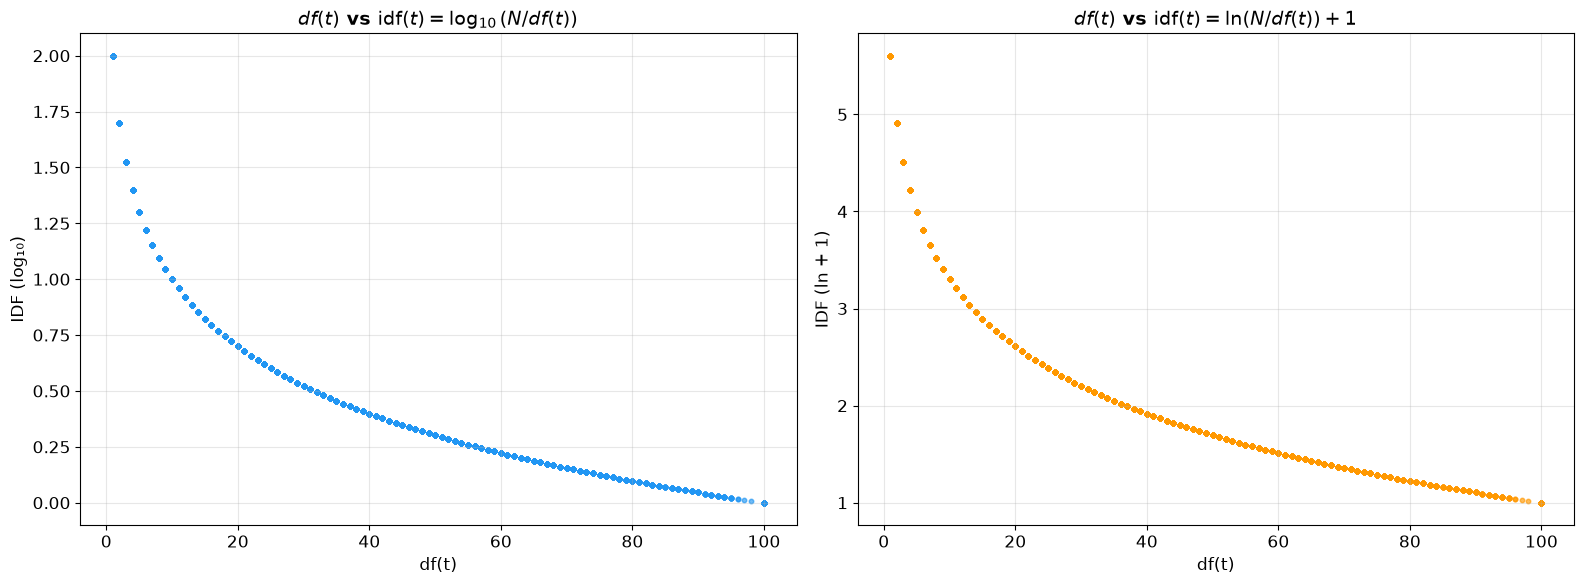

In [12]:
# Scatter plot: df(t) vs IDF
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(df_valido["df(t)"], df_valido["idf log₁₀(N/df(t))"],
                alpha=0.4, s=10, color="#2196F3")
axes[0].set_title(r"$df(t)$ vs $\mathrm{idf}(t) = \log_{10}(N/df(t))$",
                  fontsize=14, fontweight="bold")
axes[0].set_xlabel("df(t)", fontsize=12)
axes[0].set_ylabel("IDF (log₁₀)", fontsize=12)
axes[0].grid(alpha=0.3)

axes[1].scatter(df_valido["df(t)"], df_valido["idf ln(N/df(t))+1"],
                alpha=0.4, s=10, color="#FF9800")
axes[1].set_title(r"$df(t)$ vs $\mathrm{idf}(t) = \ln(N/df(t)) + 1$",
                  fontsize=14, fontweight="bold")
axes[1].set_xlabel("df(t)", fontsize=12)
axes[1].set_ylabel("IDF (ln + 1)", fontsize=12)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Comparación entre ambas fórmulas de IDF

Analizamos las diferencias entre las dos fórmulas de IDF.

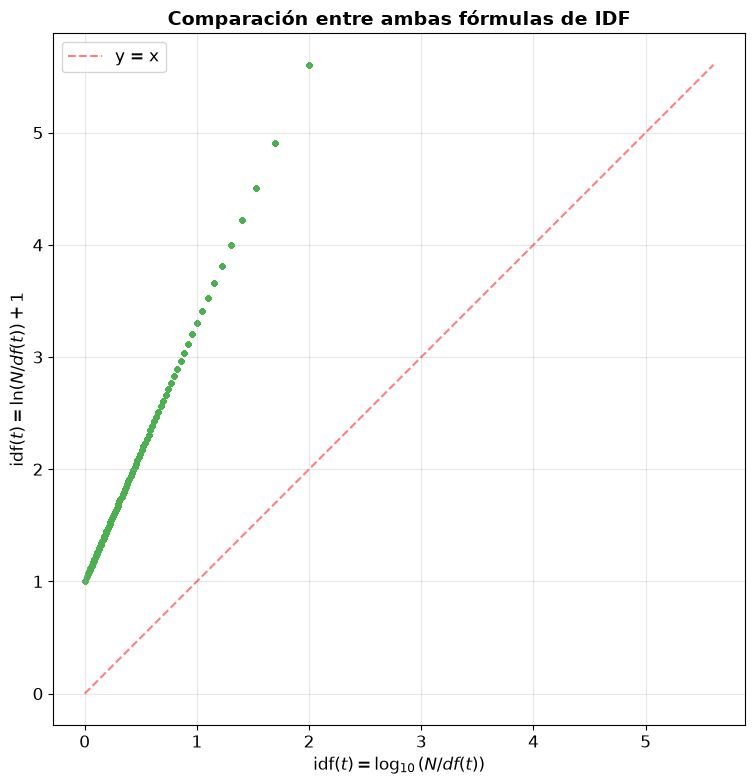


Correlación entre ambas fórmulas: 1.000000


In [13]:
# Scatter plot comparando ambas fórmulas
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(df_valido["idf log₁₀(N/df(t))"],
           df_valido["idf ln(N/df(t))+1"],
           alpha=0.3, s=10, color="#4CAF50")

# Línea de referencia
lim_min = min(df_valido["idf log₁₀(N/df(t))"].min(),
              df_valido["idf ln(N/df(t))+1"].min())
lim_max = max(df_valido["idf log₁₀(N/df(t))"].max(),
              df_valido["idf ln(N/df(t))+1"].max())
ax.plot([lim_min, lim_max], [lim_min, lim_max],
        'r--', alpha=0.5, label="y = x")

ax.set_title("Comparación entre ambas fórmulas de IDF",
             fontsize=14, fontweight="bold")
ax.set_xlabel(r"$\mathrm{idf}(t) = \log_{10}(N/df(t))$", fontsize=12)
ax.set_ylabel(r"$\mathrm{idf}(t) = \ln(N/df(t)) + 1$", fontsize=12)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
ax.set_aspect('equal')

plt.tight_layout()
plt.show()

# Correlación
correlacion = df_valido["idf log₁₀(N/df(t))"].corr(
    df_valido["idf ln(N/df(t))+1"]
)
print(f"\nCorrelación entre ambas fórmulas: {correlacion:.6f}")

---
## 10. Cálculo del TF-IDF

Combinamos el TF y el IDF para obtener el peso **TF-IDF** de cada término en cada documento:

$$\text{tf-idf}(t, d) = \text{tf}(t, d) \times \text{idf}(t)$$

Calculamos 4 variantes combinando las opciones de TF e IDF:

| Variante | TF | IDF |
|---|---|---|
| V1 | TF crudo | log₁₀(N/df) |
| V2 | TF crudo | ln(N/df)+1 |
| V3 | TF normalizado | log₁₀(N/df) |
| V4 | TF normalizado | ln(N/df)+1 |

In [14]:
# ── Calcular TF-IDF para términos seleccionados en documentos de muestra ──
terminos_tfidf = ["the", "love", "war", "god", "death", "king",
                  "moon", "science", "dream", "ocean"]
docs_tfidf = list(documentos.keys())[:10]

filas_tfidf = []
for doc in docs_tfidf:
    doc_nombre = Path(doc).name
    for t in terminos_tfidf:
        tf_raw = tf_crudo[doc].get(t, 0)
        tf_n = tf_norm[doc].get(t, 0.0)
        idf_v1 = idf_log10.get(t, 0)
        idf_v2 = idf_ln1.get(t, 0)

        filas_tfidf.append({
            "Documento": doc_nombre,
            "Término": t,
            "TF crudo": tf_raw,
            "TF norm": round(tf_n, 6),
            "IDF log₁₀": round(idf_v1, 6),
            "IDF ln+1": round(idf_v2, 6),
            "TF-IDF (crudo×log₁₀)": round(tf_raw * idf_v1, 6),
            "TF-IDF (crudo×ln+1)": round(tf_raw * idf_v2, 6),
            "TF-IDF (norm×log₁₀)": round(tf_n * idf_v1, 6),
            "TF-IDF (norm×ln+1)": round(tf_n * idf_v2, 6)
        })

df_tfidf = pd.DataFrame(filas_tfidf)

print("Tabla TF-IDF completa (muestra):")
print(f"N = {N} documentos\n")
display(df_tfidf)

Tabla TF-IDF completa (muestra):
N = 100 documentos



,Documento,Término,TF crudo,TF norm,IDF log₁₀,IDF ln+1,TF-IDF (crudo×log₁₀),TF-IDF (crudo×ln+1),TF-IDF (norm×log₁₀),TF-IDF (norm×ln+1)
0,pg10000.txt,the,1144,1.000000,0.000000,1.000000,0.000000,1144.000000,0.000000,1.000000
1,pg10000.txt,love,0,0.000000,0.075721,1.174353,0.000000,0.000000,0.000000,0.000000
2,pg10000.txt,war,18,0.015734,0.119186,1.274437,2.145355,22.939863,0.001875,0.020052
3,pg10000.txt,god,15,0.013112,0.136677,1.314711,2.050157,19.720661,0.001792,0.017238
4,pg10000.txt,death,17,0.014860,0.060481,1.139262,1.028173,19.367455,0.000899,0.016930
5,pg10000.txt,king,21,0.018357,0.124939,1.287682,2.623713,27.041324,0.002293,0.023638
6,pg10000.txt,moon,0,0.000000,0.148742,1.342490,0.000000,0.000000,0.000000,0.000000
7,pg10000.txt,science,0,0.000000,0.251812,1.579818,0.000000,0.000000,0.000000,0.000000
8,pg10000.txt,dream,0,0.000000,0.173925,1.400478,0.000000,0.000000,0.000000,0.000000
9,pg10000.txt,ocean,0,0.000000,0.244125,1.562119,0.000000,0.000000,0.000000,0.000000


In [15]:
# ── Matrices TF-IDF como tablas pivote ──

print("Matriz TF-IDF (TF crudo × IDF log₁₀):")
pivot_v1 = df_tfidf.pivot(index="Documento", columns="Término",
                          values="TF-IDF (crudo×log₁₀)")
pivot_v1 = pivot_v1[terminos_tfidf]
display(pivot_v1)

print("\nMatriz TF-IDF (TF crudo × IDF ln+1):")
pivot_v2 = df_tfidf.pivot(index="Documento", columns="Término",
                          values="TF-IDF (crudo×ln+1)")
pivot_v2 = pivot_v2[terminos_tfidf]
display(pivot_v2)

print("\nMatriz TF-IDF (TF normalizado × IDF log₁₀):")
pivot_v3 = df_tfidf.pivot(index="Documento", columns="Término",
                          values="TF-IDF (norm×log₁₀)")
pivot_v3 = pivot_v3[terminos_tfidf]
display(pivot_v3)

print("\nMatriz TF-IDF (TF normalizado × IDF ln+1):")
pivot_v4 = df_tfidf.pivot(index="Documento", columns="Término",
                          values="TF-IDF (norm×ln+1)")
pivot_v4 = pivot_v4[terminos_tfidf]
display(pivot_v4)

Matriz TF-IDF (TF crudo × IDF log₁₀):


Término,the,love,war,god,death,king,moon,science,dream,ocean
Documento,,,,,,,,,,
pg10000.txt,0.000000,0.000000,2.145355,2.050157,1.028173,2.623713,0.000000,0.000000,0.000000,0.000000
pg10001.txt,0.000000,0.000000,0.000000,1.776803,0.120961,0.374816,0.000000,0.000000,0.000000,0.244125
pg10002.txt,0.000000,0.605766,0.000000,2.186834,0.665288,0.000000,4.016025,0.000000,0.347850,0.732375
pg10003.txt,0.000000,0.530045,3.456406,0.136677,0.846730,4.372856,0.000000,0.503624,0.347850,0.244125
pg10004.txt,0.000000,4.467522,1.311050,20.228217,1.028173,1.624204,0.297483,3.273556,2.782803,0.732375
pg10005.txt,0.000000,2.271621,0.238373,0.546709,0.967692,0.374816,24.691114,8.813419,0.347850,5.859003
pg10006.txt,0.000000,4.316081,0.119186,1.503449,0.423365,0.124939,0.000000,0.000000,0.000000,0.244125
pg10007.txt,0.000000,0.984369,0.000000,0.956740,0.907211,0.000000,1.189933,0.251812,2.608878,0.000000
pg10008.txt,0.000000,0.227162,0.834305,3.826960,0.846730,0.124939,0.743708,1.259060,0.869626,2.685377



Matriz TF-IDF (TF crudo × IDF ln+1):


Término,the,love,war,god,death,king,moon,science,dream,ocean
Documento,,,,,,,,,,
pg10000.txt,1144.000000,0.000000,22.939863,19.720661,19.367455,27.041324,0.000000,0.000000,0.000000,0.000000
pg10001.txt,460.000000,0.000000,0.000000,17.091240,2.278524,3.863046,0.000000,0.000000,0.000000,1.562119
pg10002.txt,3848.000000,9.394827,0.000000,21.035372,12.531883,0.000000,36.247238,0.000000,2.800955,4.686357
pg10003.txt,4244.000000,8.220474,36.958669,1.314711,15.949669,45.068873,0.000000,3.159637,2.800955,1.562119
pg10004.txt,3496.000000,69.286850,14.018805,194.577190,19.367455,16.739867,2.684981,20.537640,22.407641,4.686357
pg10005.txt,4958.000000,35.230602,2.548874,5.258843,18.228193,3.863046,222.853391,55.293647,2.800955,37.490854
pg10006.txt,823.000000,66.938143,1.274437,14.461818,7.974834,1.287682,0.000000,0.000000,0.000000,1.562119
pg10007.txt,1609.000000,15.266594,0.000000,9.202975,17.088931,0.000000,10.739922,1.579818,21.007163,0.000000
pg10008.txt,4836.000000,3.523060,8.921058,36.811901,15.949669,1.287682,6.712452,7.899092,7.002388,17.183308



Matriz TF-IDF (TF normalizado × IDF log₁₀):


Término,the,love,war,god,death,king,moon,science,dream,ocean
Documento,,,,,,,,,,
pg10000.txt,0.000000,0.000000,0.001875,0.001792,0.000899,0.002293,0.000000,0.000000,0.000000,0.000000
pg10001.txt,0.000000,0.000000,0.000000,0.003863,0.000263,0.000815,0.000000,0.000000,0.000000,0.000531
pg10002.txt,0.000000,0.000157,0.000000,0.000568,0.000173,0.000000,0.001044,0.000000,0.000090,0.000190
pg10003.txt,0.000000,0.000125,0.000814,0.000032,0.000200,0.001030,0.000000,0.000119,0.000082,0.000058
pg10004.txt,0.000000,0.001278,0.000375,0.005786,0.000294,0.000465,0.000085,0.000936,0.000796,0.000209
pg10005.txt,0.000000,0.000458,0.000048,0.000110,0.000195,0.000076,0.004980,0.001778,0.000070,0.001182
pg10006.txt,0.000000,0.005244,0.000145,0.001827,0.000514,0.000152,0.000000,0.000000,0.000000,0.000297
pg10007.txt,0.000000,0.000612,0.000000,0.000595,0.000564,0.000000,0.000740,0.000157,0.001621,0.000000
pg10008.txt,0.000000,0.000047,0.000173,0.000791,0.000175,0.000026,0.000154,0.000260,0.000180,0.000555



Matriz TF-IDF (TF normalizado × IDF ln+1):


Término,the,love,war,god,death,king,moon,science,dream,ocean
Documento,,,,,,,,,,
pg10000.txt,1.000000,0.000000,0.020052,0.017238,0.016930,0.023638,0.000000,0.000000,0.000000,0.000000
pg10001.txt,1.000000,0.000000,0.000000,0.037155,0.004953,0.008398,0.000000,0.000000,0.000000,0.003396
pg10002.txt,1.000000,0.002441,0.000000,0.005467,0.003257,0.000000,0.009420,0.000000,0.000728,0.001218
pg10003.txt,1.000000,0.001937,0.008708,0.000310,0.003758,0.010619,0.000000,0.000744,0.000660,0.000368
pg10004.txt,1.000000,0.019819,0.004010,0.055657,0.005540,0.004788,0.000768,0.005875,0.006410,0.001340
pg10005.txt,1.000000,0.007106,0.000514,0.001061,0.003677,0.000779,0.044948,0.011152,0.000565,0.007562
pg10006.txt,1.000000,0.081334,0.001549,0.017572,0.009690,0.001565,0.000000,0.000000,0.000000,0.001898
pg10007.txt,1.000000,0.009488,0.000000,0.005720,0.010621,0.000000,0.006675,0.000982,0.013056,0.000000
pg10008.txt,1.000000,0.000729,0.001845,0.007612,0.003298,0.000266,0.001388,0.001633,0.001448,0.003553


## 11. Visualización del TF-IDF

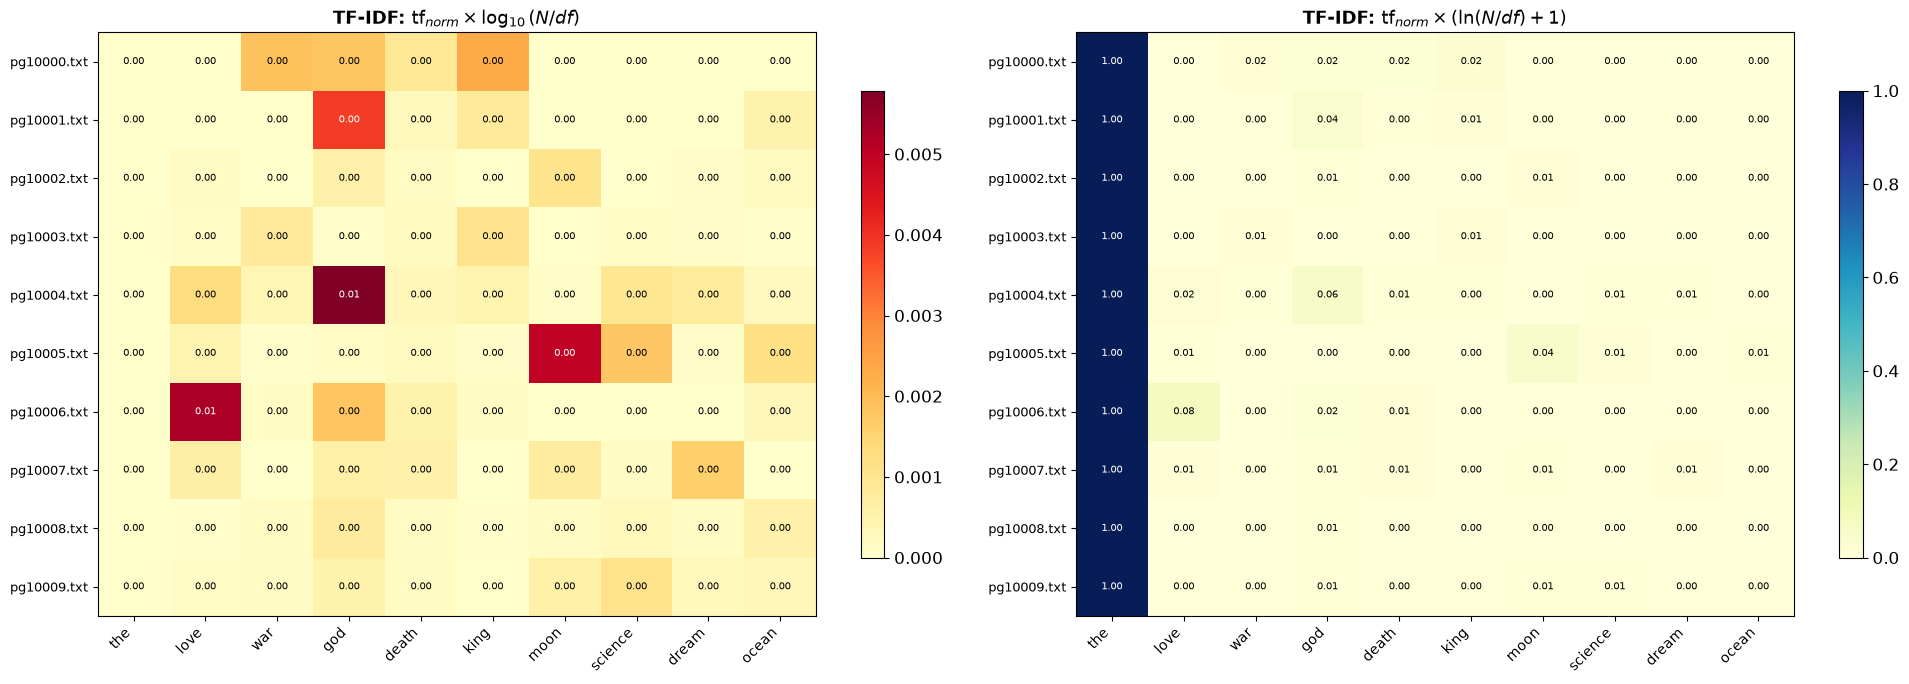

In [16]:
# ── Heatmap de la matriz TF-IDF (TF normalizado × IDF log₁₀) ──
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Heatmap V3: TF norm × IDF log₁₀
im1 = axes[0].imshow(pivot_v3.values, cmap="YlOrRd", aspect="auto")
axes[0].set_title(r"TF-IDF: $\mathrm{tf}_{norm} \times \log_{10}(N/df)$",
                  fontsize=13, fontweight="bold")
axes[0].set_xticks(range(len(terminos_tfidf)))
axes[0].set_xticklabels(terminos_tfidf, rotation=45, ha="right", fontsize=10)
axes[0].set_yticks(range(len(pivot_v3.index)))
axes[0].set_yticklabels([Path(d).name if '/' not in d else d for d in pivot_v3.index],
                        fontsize=9)
plt.colorbar(im1, ax=axes[0], shrink=0.8)

# Anotar valores
for i in range(len(pivot_v3.index)):
    for j in range(len(terminos_tfidf)):
        val = pivot_v3.values[i, j]
        color = "white" if val > pivot_v3.values.max() * 0.6 else "black"
        axes[0].text(j, i, f"{val:.2f}", ha="center", va="center",
                     fontsize=7, color=color)

# Heatmap V4: TF norm × IDF ln+1
im2 = axes[1].imshow(pivot_v4.values, cmap="YlGnBu", aspect="auto")
axes[1].set_title(r"TF-IDF: $\mathrm{tf}_{norm} \times (\ln(N/df) + 1)$",
                  fontsize=13, fontweight="bold")
axes[1].set_xticks(range(len(terminos_tfidf)))
axes[1].set_xticklabels(terminos_tfidf, rotation=45, ha="right", fontsize=10)
axes[1].set_yticks(range(len(pivot_v4.index)))
axes[1].set_yticklabels([Path(d).name if '/' not in d else d for d in pivot_v4.index],
                        fontsize=9)
plt.colorbar(im2, ax=axes[1], shrink=0.8)

# Anotar valores
for i in range(len(pivot_v4.index)):
    for j in range(len(terminos_tfidf)):
        val = pivot_v4.values[i, j]
        color = "white" if val > pivot_v4.values.max() * 0.6 else "black"
        axes[1].text(j, i, f"{val:.2f}", ha="center", va="center",
                     fontsize=7, color=color)

plt.tight_layout()
plt.show()

In [17]:
# ── Top 10 términos con mayor TF-IDF por documento (primeros 5 docs) ──
print("Top 10 términos con mayor TF-IDF (TF norm × IDF log₁₀) por documento:")
print(f"{'='*80}\n")

for doc in docs_tfidf[:5]:
    doc_nombre = Path(doc).name
    # Calcular TF-IDF para todos los términos del documento
    tfidf_doc = {}
    for termino, freq_norm in tf_norm[doc].items():
        idf_val = idf_log10.get(termino, 0)
        tfidf_doc[termino] = freq_norm * idf_val

    # Ordenar por TF-IDF descendente
    top_10 = sorted(tfidf_doc.items(), key=lambda x: x[1], reverse=True)[:10]

    print(f"📄 {doc_nombre}:")
    tabla_top = pd.DataFrame([
        {
            "Término": t,
            "TF norm": tf_norm[doc][t],
            "IDF log₁₀": idf_log10[t],
            "TF-IDF": score
        }
        for t, score in top_10
    ])
    display(tabla_top)
    print()

Top 10 términos con mayor TF-IDF (TF norm × IDF log₁₀) por documento:

📄 pg10000.txt:


,Término,TF norm,IDF log₁₀,TF-IDF
0,barons,0.058566,1.045757,0.061246
1,wardship,0.019231,2.000000,0.038462
2,aforesaid,0.028846,0.886057,0.025559
3,justiciar,0.012238,2.000000,0.024476
4,heirs,0.030594,0.721246,0.022066
5,amerced,0.010490,2.000000,0.020979
6,liberties,0.025350,0.823909,0.020886
7,debtor,0.015734,1.221849,0.019225
8,bailiffs,0.012238,1.522879,0.018637
9,heir,0.033217,0.537602,0.017857



📄 pg10001.txt:


,Término,TF norm,IDF log₁₀,TF-IDF
0,claudius,0.071739,1.397940,0.100287
1,apocolocyntosis,0.013043,2.000000,0.026087
2,aeacus,0.013043,2.000000,0.026087
3,sidenote,0.015217,1.522879,0.023174
4,footnote,0.041304,0.552842,0.022835
5,caligula,0.013043,1.698970,0.022160
6,silanus,0.010870,2.000000,0.021739
7,pedo,0.010870,2.000000,0.021739
8,hercules,0.021739,0.823909,0.017911
9,claudii,0.008696,2.000000,0.017391



📄 pg10002.txt:


,Término,TF norm,IDF log₁₀,TF-IDF
0,tonnison,0.010915,2.000000,0.021830
1,pepper,0.021050,0.795880,0.016753
2,pit,0.018191,0.481486,0.008759
3,i,0.595634,0.013228,0.007879
4,gardens,0.011954,0.494850,0.005916
5,swine,0.008316,0.677781,0.005636
6,my,0.177755,0.031517,0.005602
7,had,0.167879,0.031517,0.005291
8,kennel,0.003898,1.301030,0.005072
9,pad,0.004678,1.000000,0.004678



📄 pg10003.txt:


,Término,TF norm,IDF log₁₀,TF-IDF
0,waddington,0.016730,2.000000,0.033459
1,w,0.064326,0.346787,0.022307
2,freycinet,0.008247,2.000000,0.016494
3,orsay,0.009189,1.698970,0.015613
4,madame,0.025448,0.602060,0.015321
5,marshal,0.020971,0.721246,0.015125
6,quai,0.009189,1.522879,0.013994
7,macmahon,0.008483,1.522879,0.012918
8,ambassador,0.013666,0.853872,0.011669
9,duc,0.007540,1.522879,0.011483



📄 pg10004.txt:


,Término,TF norm,IDF log₁₀,TF-IDF
0,spiritual,0.035469,0.408935,0.014505
1,ideals,0.011728,0.920819,0.010799
2,church,0.046911,0.173925,0.008159
3,jesus,0.010297,0.721246,0.007427
4,economic,0.006579,1.045757,0.006880
5,social,0.022025,0.309804,0.006823
6,processional,0.004005,1.698970,0.006804
7,god,0.042334,0.136677,0.005786
8,revival,0.004577,1.154902,0.005286
9,sin,0.013158,0.376751,0.004957


---
## 12. Conclusiones

### Sobre el TF (Term Frequency)

- El **TF crudo** refleja la frecuencia absoluta de un término en un documento. Palabras como *the*, *of*, *and* dominan en todos los documentos.
- El **TF normalizado** (dividido por el máximo) escala los valores al rango [0, 1], permitiendo comparaciones más justas entre documentos de distinto tamaño.

### Sobre el IDF (Inverse Document Frequency)

1. **Términos muy frecuentes** (como *the*, *of*, *and*) que aparecen en casi todos los documentos tienen un IDF cercano a 0 en la fórmula `log₁₀`, y cercano a 1 en la fórmula `ln+1`. Esto refleja que aportan poca información discriminante.

2. **Términos raros** que aparecen en pocos documentos tienen un IDF alto, lo cual indica su alto poder discriminante.

3. La fórmula `ln(N/df(t)) + 1` produce valores más altos que `log₁₀(N/df(t))` debido a:
   - El logaritmo natural (ln) produce valores mayores que log₁₀ para el mismo argumento (ln(x) ≈ 2.3026 × log₁₀(x)).
   - El sumando +1 desplaza todos los valores hacia arriba, garantizando que el IDF nunca sea cero.

4. Ambas fórmulas están **perfectamente correlacionadas**, lo que significa que el ranking relativo de los términos es idéntico con ambas.

### Sobre el TF-IDF

5. El **TF-IDF** combina ambas métricas, penalizando los términos que aparecen en muchos documentos (bajo IDF) y premiando los que son frecuentes en pocos documentos específicos.

6. Los términos con mayor TF-IDF en cada documento tienden a ser los más **representativos y discriminantes** de ese documento — son frecuentes localmente pero raros globalmente.

7. Las 4 variantes de TF-IDF (combinando TF crudo/normalizado con ambas fórmulas de IDF) producen rankings similares, siendo la versión **TF normalizado × IDF** la más utilizada en la práctica para evitar sesgos por tamaño del documento.